In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

df = pd.read_csv("D:\TelcoCustomer__Churn_Datasets\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()
print("Shape:", df.shape)

Shape: (7043, 21)


<>:9: SyntaxWarning: invalid escape sequence '\T'
<>:9: SyntaxWarning: invalid escape sequence '\T'
C:\Users\a\AppData\Local\Temp\ipykernel_20644\4035517931.py:9: SyntaxWarning: invalid escape sequence '\T'
  df = pd.read_csv("D:\TelcoCustomer__Churn_Datasets\WA_Fn-UseC_-Telco-Customer-Churn.csv")


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [27]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [28]:
df.duplicated().sum()

0

In [29]:
# تحويل القيم في عمود TotalCharges الى قيم رقمية واستبدال القيم الفارغة ب 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [30]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [31]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


In [32]:
# معدل التسرب العام
overall_churn_rate = (df['Churn'] == 'Yes').mean() * 100
print('معدل التسرب العام')
print(f"{overall_churn_rate:.2f}%")

معدل التسرب العام
26.54%


In [37]:
contract_churn = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).round(2)
print("---نسبة التسرب حسب نوع العقد---")
print(contract_churn)
      

---نسبة التسرب حسب نوع العقد---
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

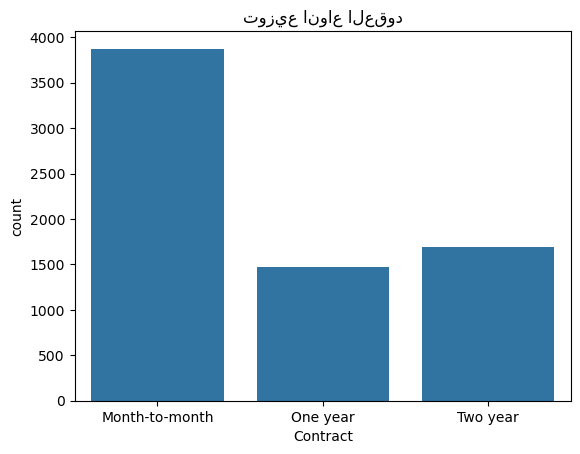

In [38]:
sns.countplot(data=df, x='Contract')
plt.title('توزيع انواع العقود')
plt.show

In [39]:
# معدل التسرب حسب خدمة الانترنت
internet_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).round(2)
print("عدل التسرب حسب نوع الخدمة")
print(internet_churn)

عدل التسرب حسب نوع الخدمة
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64


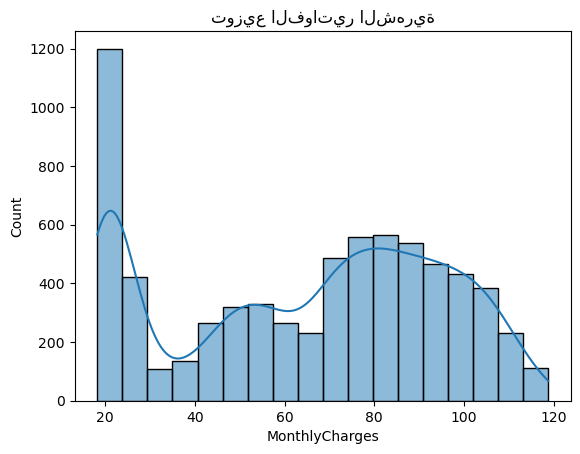

In [41]:
sns.histplot(df['MonthlyCharges'], kde=True)
plt.title('توزيع الفواتير الشهرية')
plt.show()

In [40]:
avg_tenure_churn =  df[df['Churn'] == 'Yes']['tenure'].mean()
avg_tenure_retained = df[df['Churn'] == 'No']['tenure'].mean()

print(f"Leaver Stay Customers Average: {avg_tenure_churn:.1f} Month")
print(f"Continoue Customers Average: {avg_tenure_retained:.1f} Month")

Leaver Stay Customers Average: 18.0 Month
Continoue Customers Average: 37.6 Month


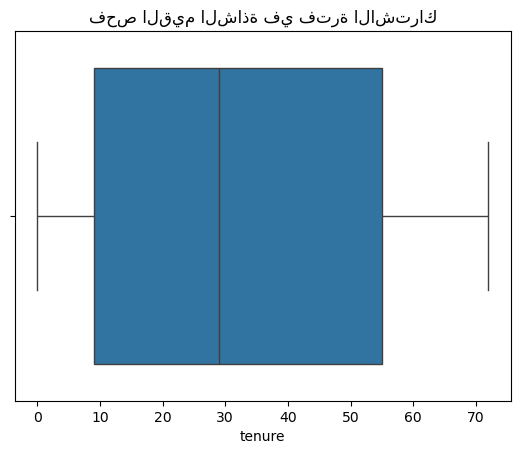

In [42]:
sns.boxplot(x=df['tenure'])
plt.title('فحص القيم الشاذة في فترة الاشتراك')
plt.show()

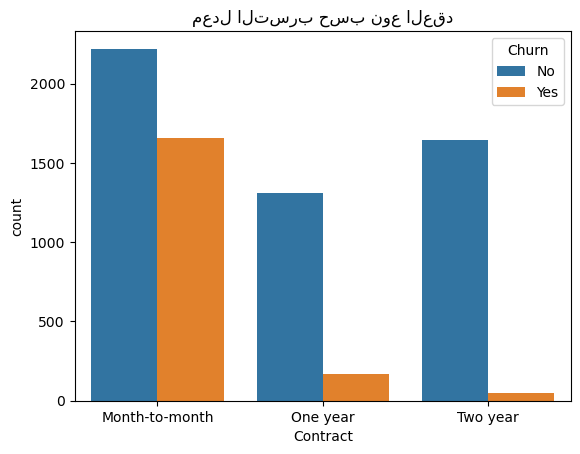

In [43]:
# علاقة نوع العقد بالتسرب
pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('معدل التسرب حسب نوع العقد')
plt.show()

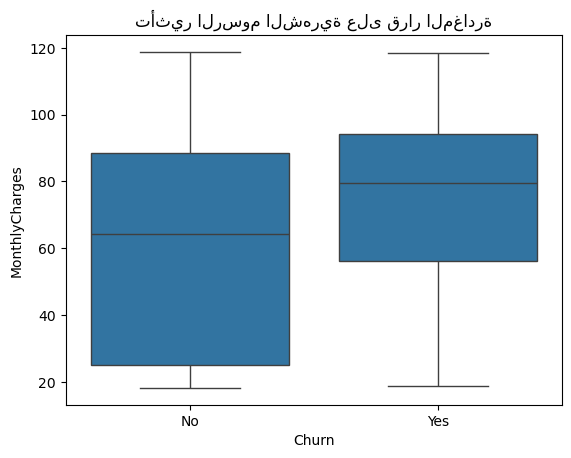

In [44]:
# توزيع الفواتير بين من تسربوا ومن بقوا
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('تأثير الرسوم الشهرية على قرار المغادرة')
plt.show()

In [48]:
# اعداد وتقسيم البيانات لتدريب النموذج

df = pd.read_csv('D:\TelcoCustomer__Churn_Datasets\WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)

# تحديد المتغير التابع (Target) والمتغيرات المستقلة (Features)
y = (df['Churn'] == 'Yes').astype(int)
X_features = df.drop(columns=['customerID', 'Churn'])

# تحويل الكلمات إلى أرقام (One-Hot Encoding)
X = pd.get_dummies(X_features, drop_first=True)

# تقسيم البيانات إلى 80% تدريب و 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"حجم بيانات التدريب: {X_train.shape[0]} صف")
print(f"حجم بيانات الاختبار: {X_test.shape[0]} صف")

<>:3: SyntaxWarning: invalid escape sequence '\T'
<>:3: SyntaxWarning: invalid escape sequence '\T'
C:\Users\a\AppData\Local\Temp\ipykernel_20644\122994439.py:3: SyntaxWarning: invalid escape sequence '\T'
  df = pd.read_csv('D:\TelcoCustomer__Churn_Datasets\WA_Fn-UseC_-Telco-Customer-Churn.csv')


حجم بيانات التدريب: 5634 صف
حجم بيانات الاختبار: 1409 صف


In [50]:
# تدريب نموذج Random Forest وتقيم الأداء

# تدريب النموذج
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)

# التنبؤ على بيانات الاختبار
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# حساب مؤشرات الدقة
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"دقة النموذج العامة (Accuracy): {acc * 100:.2f}%")
print(f"مقياس جودة التمييز(ROC_AUC Score): {roc_auc:.4f}")

دقة النموذج العامة (Accuracy): 79.35%
مقياس جودة التمييز(ROC_AUC Score): 0.8418


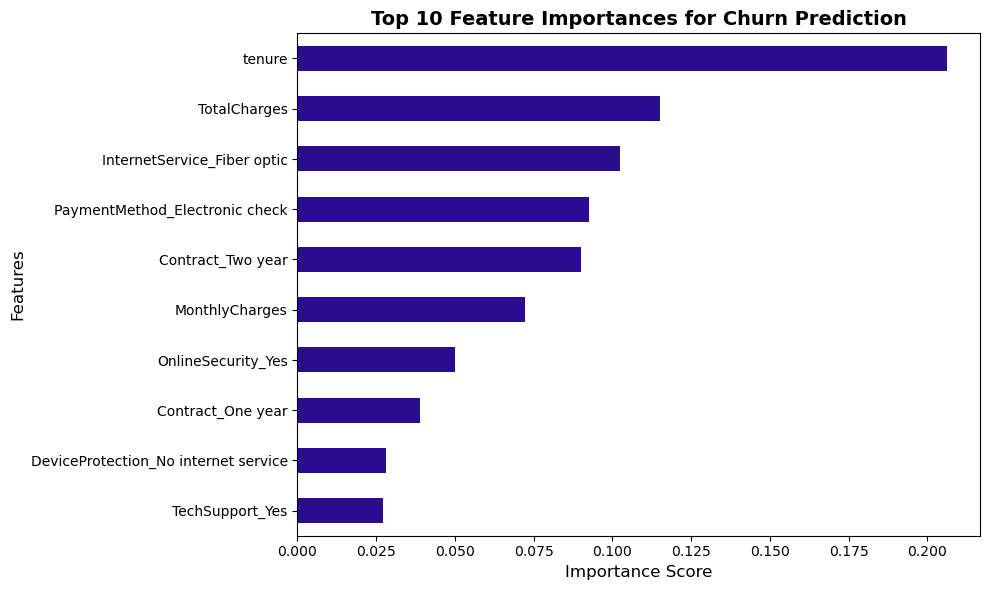

In [52]:
# حساب اهمية المتغيرات 
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
top_10 = importances.tail(10)

# المخطط البياني
plt.figure(figsize=(10, 6))
top_10.plot(kind='barh', color='#2b0b8f')
plt.title('Top 10 Feature Importances for Churn Prediction', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()                        


In [53]:
# حساب احتمال التسرب لجميع العملاء في قاعدة البيانات
df['Churn_Probability'] = np.round(rf_model.predict_proba(X)[:, 1], 4)

# دالة لتصنيف شريحة الخطر
def assign_risk_category(prob):
    if prob >= 0.70:
        return 'High Risk'
    elif prob >= 0.40:
        return 'Medium Risk'
    else:
        return 'Low Risk'

df['Risk_Level'] = df['Churn_Probability'].apply(assign_risk_category)

# تصدير البيانات المعالجة التي تحتوي على التنبؤات لملف CSV لاستخدامها في Power BI
df.to_csv('telco_churn_with_predictions.csv', index=False)
print("تم حفظ البيانات بنجاح في ملف: telco_churn_with_predictions.csv")

تم حفظ البيانات بنجاح في ملف: telco_churn_with_predictions.csv
